<a href="https://colab.research.google.com/github/harleycooper2006/Data-Analysis-and-Machine-Learning/blob/main/Week4_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay

In [ ]:
DATA_PATH = "/content/drive/MyDrive/CMP6202/datasets/"

df = pd.read_csv(DATA_PATH + "Heart.csv")
df = df.drop(columns=["Unnamed: 0"])

print("Shape:", df.shape)
df.head()

Shape: (303, 14)


,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


In [ ]:
print(df.isnull().sum())
print("\nTarget:")
print(df["AHD"].value_counts())

Age          0
Sex          0
ChestPain    0
RestBP       0
Chol         0
Fbs          0
RestECG      0
MaxHR        0
ExAng        0
Oldpeak      0
Slope        0
Ca           4
Thal         2
AHD          0
dtype: int64

Target:
AHD
No     164
Yes    139
Name: count, dtype: int64


In [ ]:
df = df.dropna()
df["AHD"] = df["AHD"].map({"No": 0, "Yes": 1})

print("Shape:", df.shape)
print(df["AHD"].value_counts(normalize=True).round(2))

Shape: (297, 14)
AHD
0    0.54
1    0.46
Name: proportion, dtype: float64


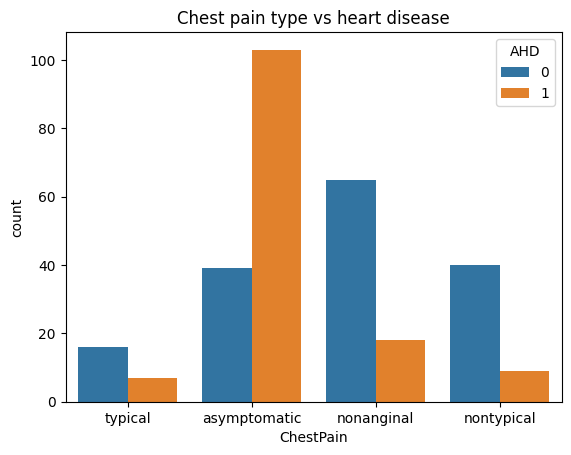

In [ ]:
sns.countplot(data=df, x="ChestPain", hue="AHD")
plt.title("Chest pain type vs heart disease")
plt.show()

In [ ]:
X = df.drop(columns=["AHD"])
y = df["AHD"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (237, 13)
X_test: (60, 13)


In [ ]:
le_chest = LabelEncoder()
X_train["ChestPain"] = le_chest.fit_transform(X_train["ChestPain"])
X_test["ChestPain"] = le_chest.transform(X_test["ChestPain"])

le_thal = LabelEncoder()
X_train["Thal"] = le_thal.fit_transform(X_train["Thal"])
X_test["Thal"] = le_thal.transform(X_test["Thal"])

print("ChestPain:", list(le_chest.classes_))
print("Thal:", list(le_thal.classes_))

ChestPain: ['asymptomatic', 'nonanginal', 'nontypical', 'typical']
Thal: ['fixed', 'normal', 'reversable']


In [ ]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print("Baseline accuracy:", accuracy_score(y_test, dummy_pred))

Baseline accuracy: 0.5333333333333333


In [ ]:
#tree model
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)

print("Decision Tree accuracy:", accuracy_score(y_test, y_pred))

Decision Tree accuracy: 0.7833333333333333


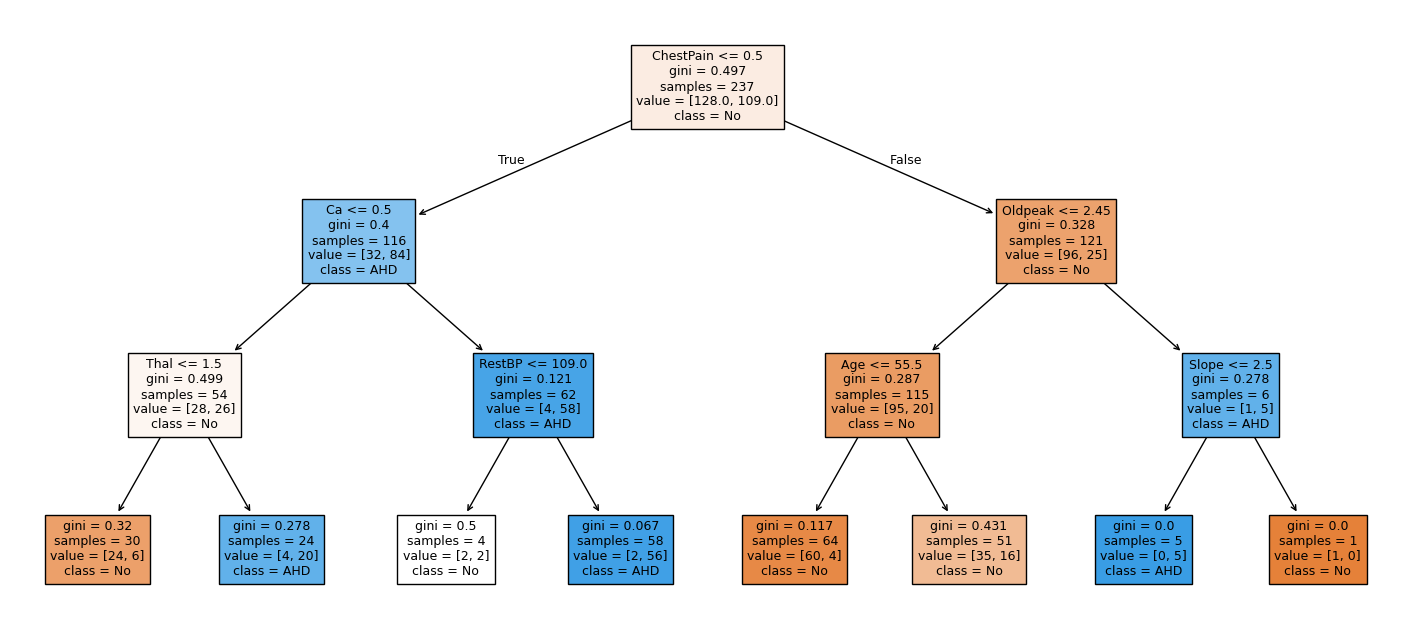

In [ ]:
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=X_train.columns, class_names=["No", "AHD"], filled=True, fontsize=9)
plt.show()

In [ ]:
p = y_train.mean()
print("Before split:", round(1- p**2 - (1-p)**2, 3))

left = y_train[X_train["ChestPain"] == 0]
p = left.mean()
print("Left (asymptomatic):", len(left), "patients, Gini = ", round(1 - p**2 - (1 - p)**2, 3))

right = y_train[X_train["ChestPain"] == 1]
p = right.mean()
print("Right (other):", len(right), "patients, Gini = ", round(1 - p**2 - (1 - p)**2, 3))

Before split: 0.497
Left (asymptomatic): 116 patients, Gini =  0.4
Right (other): 67 patients, Gini =  0.313


In [ ]:
deep_tree = DecisionTreeClassifier(random_state=42)
deep_tree.fit(X_train, y_train)

print("Deep tree    - train:", round(deep_tree.score(X_train, y_train), 3), " test:", round(deep_tree.score(X_test, y_test), 3))
print("Depth-3 tree - train:", round(tree.score(X_train, y_train), 3), " test:", round(tree.score(X_test, y_test), 3))

Deep tree    - train: 1.0  test: 0.717
Depth-3 tree - train: 0.857  test: 0.783


In [ ]:
#random tree
forest = RandomForestClassifier(n_estimators=200, random_state=42)
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)

print("Random Forest accuracy:", accuracy_score(y_test, forest_pred))

Random Forest accuracy: 0.8166666666666667


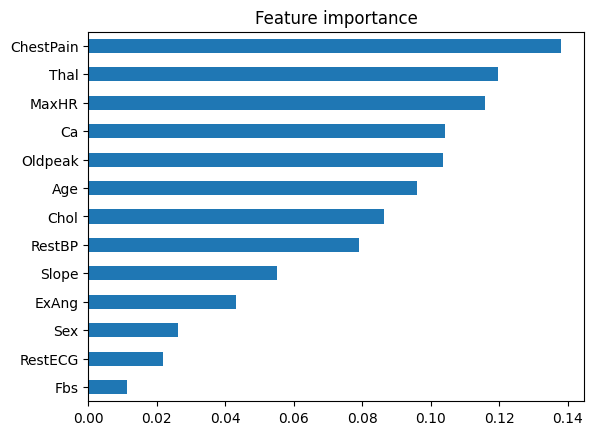

In [ ]:
importance = pd.Series(forest.feature_importances_, index=X_train.columns)
importance.sort_values().plot(kind="barh", title="Feature importance")
plt.show()

In [ ]:
boost = GradientBoostingClassifier(random_state=42)
boost.fit(X_train, y_train)
boost_pred = boost.predict(X_test)

print("Gradient Boosting accuracy:", accuracy_score(y_test, boost_pred))

Gradient Boosting accuracy: 0.7833333333333333


In [ ]:
#naive bayes
p_ahd = y_train.mean()
p_exang = X_train["ExAng"].mean()
p_exang_given_ahd = X_train["ExAng"][y_train == 1].mean()

print("P(AHD)          =", round(p_ahd, 3))
print("P(AHD  | ExAng) =", round(p_exang_given_ahd * p_ahd / p_exang, 3))

P(AHD)          = 0.46
P(AHD  | ExAng) = 0.732


In [ ]:
nb = GaussianNB()
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)

print("Naive Bayes accuracy:", accuracy_score(y_test, nb_pred))

Naive Bayes accuracy: 0.9


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
#logistical regression
log_reg = LogisticRegression()
log_reg.fit(X_train_scaled, y_train)
log_reg_pred = log_reg.predict(X_test_scaled)

print("Logistic Regression accuracy:", accuracy_score(y_test, log_reg_pred))

Logistic Regression accuracy: 0.85


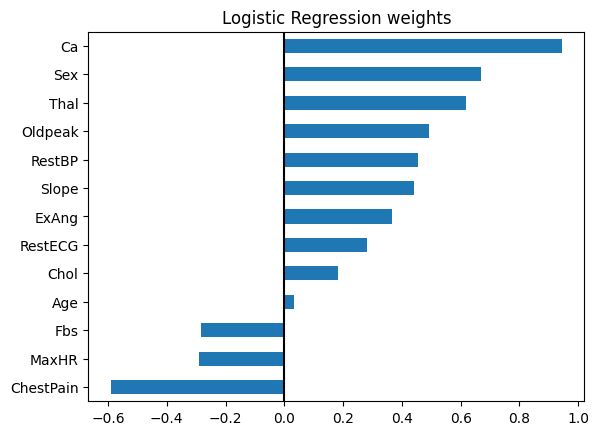

In [ ]:
weights = pd.Series(log_reg.coef_[0], index=X_train.columns)
weights.sort_values().plot(kind="barh", title="Logistic Regression weights")
plt.axvline(0, color="black")
plt.show()

In [ ]:
#K-Nearest Neighbours (KNN)
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)

print("KNN accuracy:", accuracy_score(y_test, knn_pred))

KNN accuracy: 0.9


In [ ]:
#Support Vector Machine (SVM)
svm = SVC(probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)
svm_pred = svm.predict(X_test_scaled)

print("SVM accuracy:", accuracy_score(y_test, svm_pred))

SVM accuracy: 0.8166666666666667


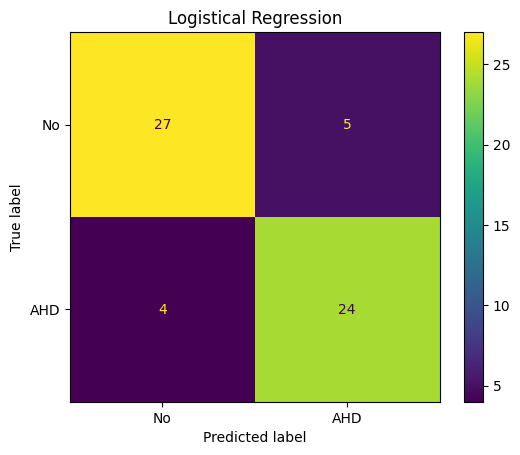

TN: 27 FP: 5 FN: 4 TP: 24


In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, log_reg_pred, display_labels=["No", "AHD"])
plt.title("Logistical Regression")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, log_reg_pred).ravel()
print("TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)

In [ ]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)

print("Accuracy :", round((tp + tn) / (tp + tn + fp + fn), 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1       :", round(2 * precision * recall / (precision + recall), 3))

Accuracy : 0.85
Precision: 0.828
Recall   : 0.857
F1       : 0.842


In [ ]:
predictions = {
    "Baseline": dummy_pred,
    "Decision Tree": y_pred,
    "Random Forest": forest_pred,
    "Gradient Boosting": boost_pred,
    "Naive Bayes": nb_pred,
    "Logistical Regression": log_reg_pred,
    "KNN": knn_pred,
    "SVM": svm_pred,
}

results = []
for name, pred in predictions.items():
    results.append([name,
                    accuracy_score(y_test, pred),
                    precision_score(y_test, pred, zero_division=0),
                    recall_score(y_test, pred),
                    f1_score(y_test, pred)])

results = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1"])
results.round(3).sort_values("Recall", ascending=False)

,Model,Accuracy,Precision,Recall,F1
6,KNN,0.900,0.867,0.929,0.897
4,Naive Bayes,0.900,0.923,0.857,0.889
5,Logistical Regression,0.850,0.828,0.857,0.842
7,SVM,0.817,0.815,0.786,0.800
2,Random Forest,0.817,0.840,0.750,0.792
3,Gradient Boosting,0.783,0.778,0.750,0.764
1,Decision Tree,0.783,0.895,0.607,0.723
0,Baseline,0.533,0.000,0.000,0.000


Logistic Regression AUC: 0.953
Decision Tree AUC       : 0.865


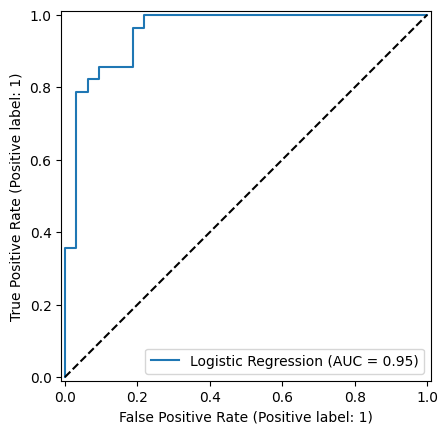

In [ ]:
log_reg_prob = log_reg.predict_proba(X_test_scaled)[:, 1]
tree_prob = tree.predict_proba(X_test)[:, 1]

print("Logistic Regression AUC:", round(roc_auc_score(y_test, log_reg_prob), 3))
print("Decision Tree AUC       :", round(roc_auc_score(y_test, tree_prob), 3))

RocCurveDisplay.from_predictions(y_test, log_reg_prob, name="Logistic Regression")
plt.plot([0, 1], [0, 1], "k--")
plt.show()

In [ ]:
pred_05 = (log_reg_prob >= 0.5).astype(int)
pred_03 = (log_reg_prob >= 0.3).astype(int)

print("Threshold 0.5:", confusion_matrix(y_test, pred_05).ravel(), " recall =", round(recall_score(y_test, pred_05), 3))
print("Threshold 0.3:", confusion_matrix(y_test, pred_03).ravel(), " recall =", round(recall_score(y_test, pred_03), 3))
print("(order: TN, FP, FN, TP)")

Threshold 0.5: [27  5  4 24]  recall = 0.857
Threshold 0.3: [26  6  2 26]  recall = 0.929
(order: TN, FP, FN, TP)


In [ ]:
new_patient = pd.DataFrame([{
    "Age": 58, "Sex": 1, "ChestPain": "asymptomatic", "RestBP": 140, "Chol": 260,
    "Fbs": 0, "RestECG": 2, "MaxHR": 125, "ExAng": 1, "Oldpeak": 2.0, "Slope": 2,
    "Ca": 1, "Thal": "reversable"
}])

In [ ]:
new_patient

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal
0,58,1,asymptomatic,140,260,0,2,125,1,2.0,2,1,reversable


In [ ]:
new_patient["ChestPain"] = le_chest.transform(new_patient["ChestPain"])
new_patient["Thal"] = le_thal.transform(new_patient["Thal"])

print("Prediction (1 = AHD):", forest.predict(new_patient)[0])
print("Probability of AHD:  ", forest.predict_proba(new_patient)[0, 1])

Prediction (1 = AHD): 1
Probability of AHD:   0.995
